In [3]:
%pip install --default-timeout=120 --retries 10 pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable
  Using cached pandas-3.1.1-cp314-cp314-win_amd64.whl.metadata (16 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached pandas-3.1.1-cp314-cp314-win_amd64.whl (10.9 MB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
from io import StringIO

path = "../data/raw/Pinterest Analytics overview 20261006-20261105.csv"
with open(path, encoding="utf-8-sig") as f:
    lines = f.read().splitlines()

def read_section(header_start):
    start = next(i for i, l in enumerate(lines) if l.startswith(header_start))
    block = []
    for l in lines[start:]:
        if l.strip() == "":      # a blank line ends the table
            break
        block.append(l)
    df = pd.read_csv(StringIO("\n".join(block)))
    return df.dropna(subset=["Impressions"]).reset_index(drop=True)  # drops the footnote line

daily  = read_section("Date,Impressions")
boards = read_section("Pinterest Link,Impressions,Engagement")
pins   = read_section("Pinterest Link,Content Type")

daily["Date"] = pd.to_datetime(daily["Date"])
for df in (daily, boards, pins):
    df["Impressions"] = df["Impressions"].astype(int)
for c in ["Engagement", "Pin clicks", "Outbound clicks", "Saves"]:
    boards[c] = boards[c].astype(int)

total = daily["Impressions"].sum()
print(total)          # should print 40936
daily.head()

41639


,Date,Impressions
0,2026-10-06,695
1,2026-10-07,574
2,2026-10-08,416
3,2026-10-09,540
4,2026-10-10,382


In [3]:
boards["board"] = boards["Pinterest Link"].str.rstrip("/").str.split("/").str[-1]
boards["engagement_rate_%"] = (boards["Engagement"] / boards["Impressions"] * 100).round(2)
boards["save_rate_%"]       = (boards["Saves"] / boards["Impressions"] * 100).round(2)
boards["outbound_ctr_%"]    = (boards["Outbound clicks"] / boards["Impressions"] * 100).round(3)
print(boards[["board", "Impressions", "Engagement", "Pin clicks", "Outbound clicks",
              "Saves", "engagement_rate_%", "outbound_ctr_%"]].head(6))

# concentration
pins_sorted = pins.sort_values("Impressions", ascending=False)
print("Top pin share %:", round(pins_sorted["Impressions"].iloc[0] / total * 100, 1))
print("Top 5 pins share %:", round(pins_sorted["Impressions"].head(5).sum() / total * 100, 1))

# the Oct 11-17 spike
peak = daily[(daily["Date"] >= "2026-10-11") & (daily["Date"] <= "2026-10-17")]["Impressions"].sum()
print("Oct 11-17 share of all impressions %:", round(peak / total * 100, 1))

              board  Impressions  Engagement  Pin clicks  Outbound clicks  \
0             nails        35231         973         803                1   
1       home-decore         3091          61          51                1   
2    _quick_creates         1656          59          57                0   
3    womens-fashion          319           6           6                0   
4  saree-collection          264           5           5                0   
5           earring          201           6           6                0   

   Saves  engagement_rate_%  outbound_ctr_%  
0    166               2.76           0.003  
1      6               1.97           0.032  
2      2               3.56           0.000  
3      0               1.88           0.000  
4      0               1.89           0.000  
5      0               2.99           0.000  
Top pin share %: 44.6
Top 5 pins share %: 64.2
Oct 11-17 share of all impressions %: 45.8


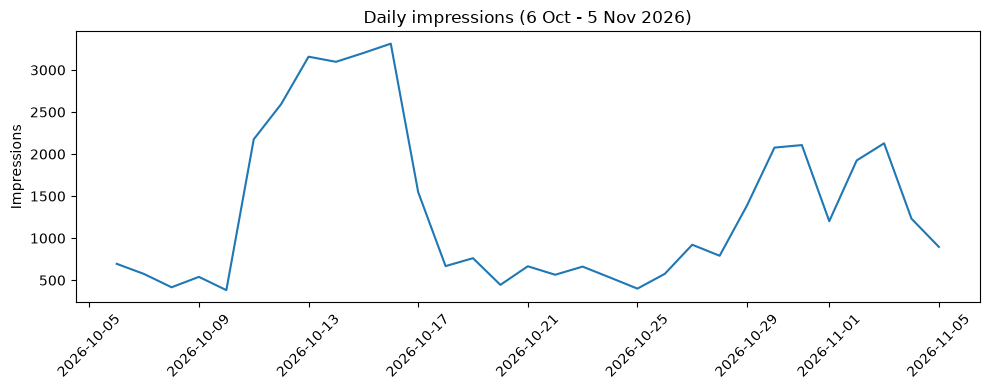

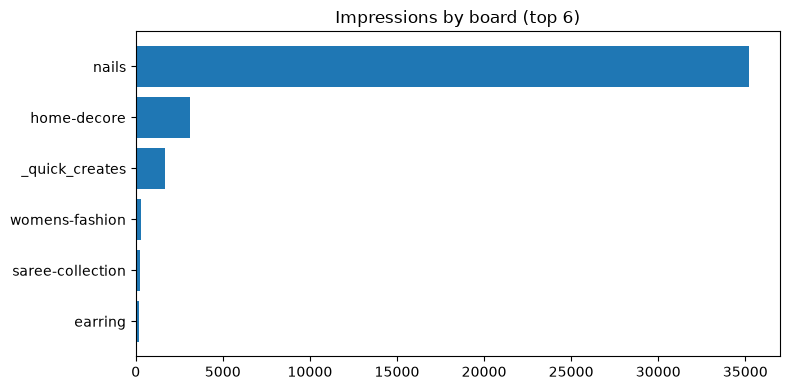

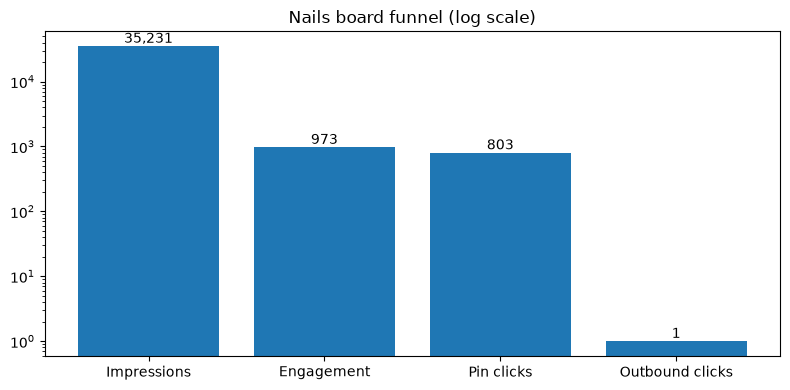

In [4]:
import matplotlib.pyplot as plt

# 1. daily trend
plt.figure(figsize=(10, 4))
plt.plot(daily["Date"], daily["Impressions"])
plt.title("Daily impressions (6 Oct - 5 Nov 2026)")
plt.ylabel("Impressions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../images/daily_impressions.png", dpi=150)
plt.show()

# 2. impressions by board
top = boards.sort_values("Impressions").tail(6)
plt.figure(figsize=(8, 4))
plt.barh(top["board"], top["Impressions"])
plt.title("Impressions by board (top 6)")
plt.tight_layout()
plt.savefig("../images/boards.png", dpi=150)
plt.show()

# 3. funnel for the nails board (log scale, because the last step is tiny)
nails = boards[boards["board"] == "nails"].iloc[0]
steps = ["Impressions", "Engagement", "Pin clicks", "Outbound clicks"]
values = [int(nails[s]) for s in steps]
plt.figure(figsize=(8, 4))
plt.bar(steps, values)
plt.yscale("log")
for i, v in enumerate(values):
    plt.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.title("Nails board funnel (log scale)")
plt.tight_layout()
plt.savefig("../images/funnel.png", dpi=150)
plt.show()